In [1]:
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import CrossEntropyLoss


import json
import numpy as np
import random
import matplotlib.pyplot as plt
import pickle

import pandas as pd
from collections import Counter

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [2]:
torch.cuda.empty_cache()

In [3]:
!nvidia-smi -L

GPU 0: NVIDIA A40 (UUID: GPU-4cbcc03c-abc8-5a22-8589-b72c3c487428)


In [4]:
file_path_philipp = '/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/'

#for good data sets, only thing to change
data_set_name = 'junker_z5_all_genes'

file_path_expression_matrix = file_path_philipp + data_set_name + '.pkl'

gene_matrix = pd.read_pickle(file_path_expression_matrix)

barcode_cont_NN_mapping_output = data_set_name + '_barcode_cont_NN_mapping.pkl'
barcode_NN_cont_mapping_output = data_set_name + '_barcode_NN_cont_mapping.pkl'
hyper_param_output = data_set_name + '_hyper_params_log.jsonl'
test_accuracy_best_hyper_params_output = data_set_name + '_test_accuracy_best_hyper_params.json'
model_weights_output = data_set_name + '_model_weights.pth'
training_dataset_output = data_set_name + '_training_dataset.pth'
test_dataset_output = data_set_name + '_test_dataset.pth'
validation_dataset_output = data_set_name + '_validation_dataset.pth'

minimal_barcode_threshold_per_class = 95


Overview of barcode_cont distribution

<class 'pandas.core.frame.DataFrame'>
Shape: (6191, 21063)


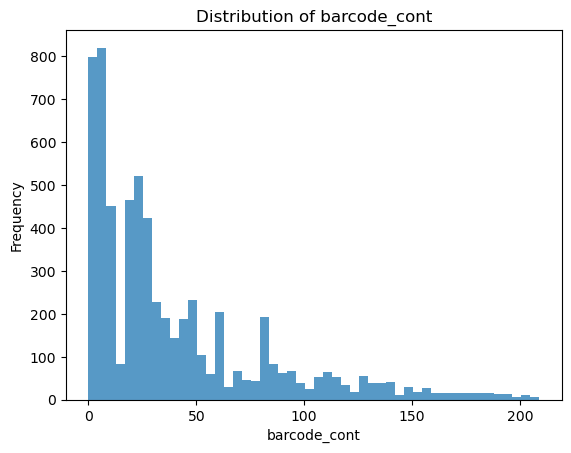

In [6]:
print(type(gene_matrix))
print("Shape:", gene_matrix.shape)
plt.hist(gene_matrix['barcode_cont'], bins=50, alpha=0.75)
plt.title('Distribution of barcode_cont')
plt.xlabel('barcode_cont')
plt.ylabel('Frequency')
plt.show()

In [7]:

counts = gene_matrix['barcode_cont'].value_counts()

#condition = (counts >= 4) & (counts <= 60)
#gene_matrix_filtered = gene_matrix[gene_matrix['barcode_cont'].isin(counts.index[condition])]

# Filter based on a dynamic threshold
gene_matrix_filtered = gene_matrix[gene_matrix['barcode_cont'].isin(counts.index[counts >= minimal_barcode_threshold_per_class])]

unique_barcodes = gene_matrix_filtered['barcode_cont'].unique()
barcode_cont_to_barcode_NN = {barcode: i for i, barcode in enumerate(unique_barcodes)}
barcode_NN_to_barcode_cont = {v: k for k, v in barcode_cont_to_barcode_NN.items()}

# Proper assignment using .loc to avoid SettingWithCopyWarning
gene_matrix_filtered.loc[:, 'barcode_NN'] = gene_matrix_filtered['barcode_cont'].map(barcode_cont_to_barcode_NN)

with open(barcode_cont_NN_mapping_output, 'wb') as f:
    pickle.dump(barcode_cont_to_barcode_NN, f)

with open(barcode_NN_cont_mapping_output, 'wb') as f:
    pickle.dump(barcode_NN_to_barcode_cont, f)


/tmp/ipykernel_2147349/2082759783.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gene_matrix_filtered.loc[:, 'barcode_NN'] = gene_matrix_filtered['barcode_cont'].map(barcode_cont_to_barcode_NN)


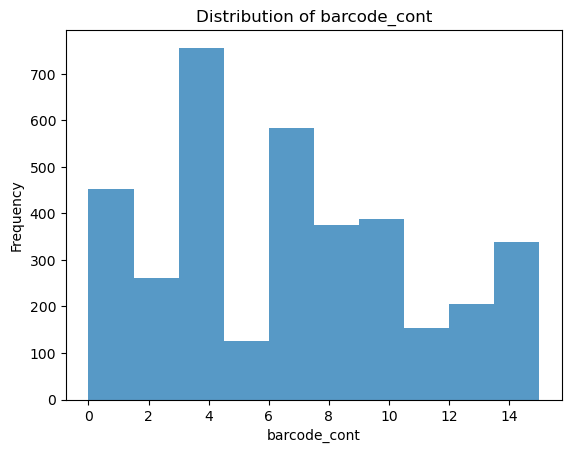

In [8]:
plt.hist(gene_matrix_filtered['barcode_NN'], bins=10, alpha=0.75)
plt.title('Distribution of barcode_cont')
plt.xlabel('barcode_cont')
plt.ylabel('Frequency')
plt.show()

In [9]:
print("Shape:", gene_matrix_filtered.shape)
print(barcode_cont_to_barcode_NN)

# Verifying if the new labels in 'barcode_cont_int' start from 0 and go up to the number of unique labels - 1.
max_label = gene_matrix_filtered['barcode_NN'].max()
unique_labels_count = gene_matrix_filtered['barcode_NN'].nunique()

# The verification condition
is_label_range_correct = (max_label == (unique_labels_count - 1))
print(f"Is the label range correct? {is_label_range_correct}")



Shape: (3635, 21064)
{0: 0, 1: 1, 2: 2, 5: 3, 6: 4, 11: 5, 12: 6, 20: 7, 24: 8, 27: 9, 28: 10, 36: 11, 38: 12, 48: 13, 62: 14, 81: 15}
Is the label range correct? True


In [10]:
gene_matrix = gene_matrix_filtered
print("Columns with missing values:")
print(gene_matrix.isnull().sum())

print("\nData types of columns:")
print(gene_matrix.dtypes)

print("\nSummary statistics for numeric columns:")
print(gene_matrix.describe())

print("\nNon-numeric column value counts:")
for column in gene_matrix.select_dtypes(include=['object']).columns:
    print(f"\nValue counts for {column}:")
    print(gene_matrix[column].value_counts())

non_numeric_columns = gene_matrix.select_dtypes(include=['object']).columns
print("\nNon-numeric columns:")
print(non_numeric_columns)

single_value_columns = [col for col in gene_matrix.columns if gene_matrix[col].nunique() == 1]
print("\nColumns with a single unique value:")
print(single_value_columns)

print("\nIndex dtype:")
print(gene_matrix.index.dtype)
print("Index unique values count:")
print(gene_matrix.index.nunique())
print("Index first 5 values:")
print(gene_matrix.index[:5])


Columns with missing values:
ptpn12          0
CU856344.1      0
mansc1          0
lrp6            0
dusp16          0
               ..
EGFP            0
dTomato         0
rfp1            0
barcode_cont    0
barcode_NN      0
Length: 21064, dtype: int64

Data types of columns:
ptpn12           float32
CU856344.1       float32
mansc1           float32
lrp6             float32
dusp16           float32
                  ...   
EGFP             float32
dTomato          float32
rfp1             float32
barcode_cont    category
barcode_NN       float64
Length: 21064, dtype: object

Summary statistics for numeric columns:
            ptpn12   CU856344.1       mansc1         lrp6       dusp16  \
count  3635.000000  3635.000000  3635.000000  3635.000000  3635.000000   
mean      0.000692     0.000742     0.005630     0.000955     0.005644   
std       0.024265     0.026660     0.093586     0.034461     0.077667   
min       0.000000     0.000000     0.000000     0.000000     0.000000   
25%   

In [11]:
class CustomDataset(Dataset):
    
    def __init__(self, dataframe, indices=None):
        if indices is not None:
            self.dataframe = dataframe.iloc[indices].reset_index(drop=True)
        else:
            self.dataframe = dataframe.copy()

        self.labels = self.dataframe['barcode_NN'].values
        self.features = self.dataframe.drop(['barcode_cont', 'barcode_NN'], axis=1).values

        
    def __len__(self):
        """
        Returns the total number of samples in the dataset.
        """
        return len(self.dataframe)
    
    def __getitem__(self, idx):
        sample = torch.tensor(self.features[idx], dtype=torch.float)  
        label = torch.tensor(self.labels[idx], dtype=torch.long)  
        return sample, label
    
    def num_classes(self):
        """
        Returns the number of unique classes in the dataset.
        """
        return np.unique(self.labels).size
        
    def num_features(self):
        """
        Returns the number of features for each sample in the dataset.
        """
        return self.features.shape[1]  

In [12]:
def get_dataSets_for_training(dataset: CustomDataset, size_test_validation_set: int = 200):
    
    total_indices = np.arange(len(dataset))
    np.random.shuffle(total_indices)

    # Calculate the size of each subset
    total_length = len(total_indices)
    size_train_set = total_length - 2 * size_test_validation_set
    train_indices = total_indices[:size_train_set]
    validation_indices = total_indices[size_train_set:size_train_set + size_test_validation_set]
    test_indices = total_indices[size_train_set + size_test_validation_set:]

    # Create datasets using the indices
    train_dataset = CustomDataset(dataset.dataframe, indices=train_indices)
    validation_dataset = CustomDataset(dataset.dataframe, indices=validation_indices)
    test_dataset = CustomDataset(dataset.dataframe, indices=test_indices)
    
    return train_dataset, train_indices, validation_dataset, validation_indices, test_dataset, test_indices


In [13]:
class Swish(nn.Module):
    def forward(self, x):
        return x * torch.sigmoid(x)

class CustomLayer(nn.Module):
    
    def __init__(self, size, dropout_rate, activation_func_name):
        super(CustomLayer, self).__init__()
        self.linear = nn.Linear(size, size)
        self.bn = nn.BatchNorm1d(size)
        self.dropout = nn.Dropout(dropout_rate)
        self.activation_func_name = activation_func_name  

        # Selecting the activation function
        if activation_func_name == 'relu':
            self.activation_func = nn.ReLU()
        elif activation_func_name == 'elu':
            self.activation_func = nn.ELU()
        elif activation_func_name == 'selu':
            self.activation_func = nn.SELU()
        elif activation_func_name == 'swish':
            self.activation_func = Swish()
        elif activation_func_name == 'mish':
            self.activation_func = nn.Mish()
        else:
            raise ValueError("Unsupported activation function")

        self.initialize_weights() 
            
    def initialize_weights(self):
        if self.activation_func_name in ['relu', 'swish', 'mish']:
            nn.init.kaiming_normal_(self.linear.weight, mode='fan_out', nonlinearity='relu')
        elif self.activation_func_name in ['elu', 'selu']:
            nn.init.kaiming_normal_(self.linear.weight, mode='fan_out', nonlinearity='leaky_relu')
        nn.init.constant_(self.linear.bias, 0)
         
    def forward(self, x):
        identity = x
        out = self.linear(x)

        out = self.bn(out)
        out = self.activation_func(out)
        out = self.dropout(out)
        out += identity  
        return out

class GeneExpressionModel(nn.Module):
         
    def __init__(self, input_dimension, num_classes, hidden_units, dropout_rate, num_layers, activation_function):
        super(GeneExpressionModel, self).__init__()

        # First layer to transform input dimension to hidden_units dimension
        self.initial_layer = nn.Linear(input_dimension, hidden_units)

        # Create a list of custom layers with residual connections
        self.layers = nn.ModuleList([CustomLayer(hidden_units, dropout_rate, activation_function) for _ in range(num_layers - 1)])
        
        # Output layer
        self.output = nn.Linear(hidden_units, num_classes) 

        with torch.no_grad():
            # Xavier initialization for the initial layer
            nn.init.kaiming_normal_(self.initial_layer.weight)
            nn.init.constant_(self.initial_layer.bias, 0)
           
            # Scaled Kaiming initialization for the output layer
            nn.init.kaiming_normal_(self.output.weight, mode='fan_out', nonlinearity='relu')
            self.output.weight.data *= 0.01  # Scaling factor
            nn.init.constant_(self.output.bias, 0)  

    def forward(self, x):
        # Pass the input through the initial layer
        x = self.initial_layer(x)

        # Pass the input through each custom layer
        for layer in self.layers:
            x = layer(x)

        # Output layer
        x = self.output(x)
        return x


In [14]:
# Function to calculate accuracy
def calculate_accuracy(model, data_loader, device):
    model.eval()  # Set the model to evaluation mode
    correct = 0
    total = 0

    with torch.no_grad():
        for data in data_loader:
            inputs, labels = data[0].to(device), data[1].to(device)
            outputs = model(inputs)

            # Get the predictions
            _, predicted = torch.max(outputs.data, 1)
            
            # Total number of labels
            total += labels.size(0)

            # Total correct predictions
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    return accuracy

def accuracy_calc(model, loader, criterion, device): 
    model.eval()  # Set the model to evaluation mode
    total_loss = 0.0
    with torch.no_grad():
        for i, data in enumerate(loader, 0):
            inputs, labels = data[0].to(device), data[1].to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            accuracy = calculate_accuracy(model, loader, device)

    return accuracy

def evaluate_model(model, loader, criterion, device):
    model.eval()  # Set the model to evaluation mode
    total_loss = 0.0
    with torch.no_grad():
        for i, data in enumerate(loader, 0):
            inputs, labels = data[0].to(device), data[1].to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
    return total_loss / len(loader)

def train_and_validate(model, train_loader, validation_loader, optimizer, scheduler, num_epochs, device, current_logging_object):
    criterion = CrossEntropyLoss()

    for epoch in range(num_epochs):
        
        model.train()
        running_loss = 0.0

        # Training loop
        for i, data in enumerate(train_loader, 0):
            inputs, labels = data[0].to(device), data[1].to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        # Print training loss
        training_loss = running_loss / len(train_loader)

        # Validation
        validation_loss = evaluate_model(model, validation_loader, criterion, device)
        scheduler.step(validation_loss)
        epoch_to_log = f'epoch_{epoch + 1}'
        current_logging_object["training_run"][epoch_to_log] = {"training_loss": training_loss, "validation_loss": validation_loss}
       
    validation_accuracy = accuracy_calc(model, validation_loader, criterion, device)   
    
    return validation_accuracy,  current_logging_object


In [15]:
complete_dataset = CustomDataset(gene_matrix_filtered)
print(len(complete_dataset))
train_dataset, train_indices, validation_dataset, validation_indices, test_dataset, test_indices = get_dataSets_for_training(complete_dataset)

num_unique_barcodes = complete_dataset.num_classes()
num_input_features = complete_dataset.num_features()
number_of_cells = len(complete_dataset)


torch.save(train_dataset, training_dataset_output)
torch.save(validation_dataset, validation_dataset_output)
torch.save(test_dataset, test_dataset_output)


3635


In [16]:

# categorical hyperparameters
batch_size_range = [8, 16, 32, 64, 128, 256]
optimizers = {
    'adam': torch.optim.Adam,
    'adamw': torch.optim.AdamW,
    'sgd': torch.optim.SGD,
    'rmsprop': torch.optim.RMSprop,
    'adagrad': torch.optim.Adagrad,
}

activation_function_range = ['relu', 'elu', 'selu', 'swish']

# sample linearly
hidden_units_range= [200, 7000]
droput_rate_range= [0.4, 0.8]
num_layers_range= [7, 40]
num_epochs_range = [5, 20]

# sample logarithmically
learning_rate_range = [0.00001, 0.001]
weight_decay_range = [0.000001, 0.001]  

# Functions for random sampling
def random_sample_categorical(range_values):
    return random.choice(range_values)

def random_sample_linear_integer(start, end):
    return int(np.round(np.random.uniform(start, end)))

def random_sample_linear(start, end):
    return np.random.uniform(start, end)
    
def random_sample_log(start, end):
    return np.random.uniform(np.log10(start), np.log10(end))

In [17]:
best_accuracy = 0
best_hyperparameters = None

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

num_experiments = 100
seed = 42 # You can choose any number as your seed value
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [18]:
with open(hyper_param_output, 'w') as file:
    pass 

for experiment in range(num_experiments):
    current_logging_object = {
    "hyperparameters": {},
    "data_overview": {},
    "training_run": {}
    }
    batch_size = random_sample_categorical(batch_size_range)
    activation_function = random_sample_categorical(activation_function_range)
    hidden_units = random_sample_linear_integer(*hidden_units_range)
    dropout_rate = random_sample_linear(*droput_rate_range)
    num_layers = random_sample_linear_integer(*num_layers_range)
    num_epochs = random_sample_linear_integer(*num_epochs_range)
    learning_rate = 10 ** random_sample_log(*learning_rate_range)
    weight_decay = 10 ** random_sample_log(*weight_decay_range)
    current_optimizer_name, current_optimizer_class = random.choice(list(optimizers.items()))
    
    current_logging_object["data_overview"]["experiment"] = experiment
    current_logging_object["data_overview"]["number_of_genes"] = num_input_features
    current_logging_object["data_overview"]["number_of_barcodes"] = num_unique_barcodes
    current_logging_object["data_overview"]["minimal_barcode_threshold_per_class"] = minimal_barcode_threshold_per_class
    current_logging_object["data_overview"]["cells"] = number_of_cells
    current_logging_object["hyperparameters"]["batch_size"] = batch_size
    current_logging_object["hyperparameters"]["activation_function"] = activation_function
    current_logging_object["hyperparameters"]["hidden_units"] = hidden_units
    current_logging_object["hyperparameters"]["dropout_rate"] = dropout_rate
    current_logging_object["hyperparameters"]["num_layers"] = num_layers
    current_logging_object["hyperparameters"]["num_epochs"] = num_epochs
    current_logging_object["hyperparameters"]["learning_rate"] = learning_rate
    current_logging_object["hyperparameters"]["weight_decay"] = weight_decay
  
    train_loader = DataLoader(train_dataset, batch_size=int(batch_size), shuffle=True, drop_last=True)
    validation_loader = DataLoader(validation_dataset, batch_size=int(batch_size), shuffle=False)    

    model = GeneExpressionModel(input_dimension=num_input_features, num_classes=num_unique_barcodes, hidden_units=hidden_units, dropout_rate=dropout_rate, num_layers=num_layers, activation_function=activation_function)
    model.to(device)
    

    optimizer = current_optimizer_class(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2, verbose=True)

    validation_accuracy_current, current_logging_object = train_and_validate(model, train_loader, validation_loader, optimizer, scheduler, num_epochs, device, current_logging_object)
    if validation_accuracy_current > best_accuracy:
        best_accuracy = validation_accuracy_current
        best_hyperparameters = current_logging_object
        torch.save(model.state_dict(), model_weights_output)
    with open(hyper_param_output, 'a') as file:  
        json.dump(current_logging_object, file)
        file.write('\n')

    del model
    del optimizer
    torch.cuda.empty_cache()


/fast/AG_Metzger/philipp/bins/miniforge3/envs/TOSICA_a40/TOSICA_a40/lib/python3.8/site-packages/torch/optim/lr_scheduler.py:60: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(
/tmp/ipykernel_2147349/157857523.py:21: DeprecationWarning: an integer is required (got type numpy.float64).  Implicit conversion to integers using __int__ is deprecated, and may be removed in a future version of Python.
  label = torch.tensor(self.labels[idx], dtype=torch.long)


After Hyperparemter Loop we load the best model weights and test the model

In [19]:
best_model = GeneExpressionModel(
    input_dimension=best_hyperparameters["data_overview"]["number_of_genes"],
    num_classes=best_hyperparameters["data_overview"]["number_of_barcodes"],
    hidden_units=best_hyperparameters["hyperparameters"]["hidden_units"],
    dropout_rate=best_hyperparameters["hyperparameters"]["dropout_rate"],
    num_layers=best_hyperparameters["hyperparameters"]["num_layers"],
    activation_function=best_hyperparameters["hyperparameters"]["activation_function"]
)
# initialize model and data loaders
batch_size = best_hyperparameters["hyperparameters"]["batch_size"]
train_loader = DataLoader(train_dataset, batch_size=int(batch_size), shuffle=True, drop_last=True)
validation_loader = DataLoader(validation_dataset, batch_size=int(batch_size), shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=int(batch_size), shuffle=False)
best_model.to(device)
model_weights_path = model_weights_output  
best_model.load_state_dict(torch.load(model_weights_path))

# Evaluate the model on the training set
training_loss = evaluate_model(best_model, train_loader, CrossEntropyLoss(), device)
training_accuracy = accuracy_calc(best_model, train_loader, CrossEntropyLoss(), device)
best_hyperparameters["training_accuracy"] = training_accuracy

# Evaluate the model on the validation set
validation_loss = evaluate_model(best_model, validation_loader, CrossEntropyLoss(), device)
validation_accuracy = accuracy_calc(best_model, validation_loader, CrossEntropyLoss(), device)
best_hyperparameters["validation_accuracy"] = validation_accuracy


# Evaluate the model on the test set
test_loss = evaluate_model(best_model, test_loader, CrossEntropyLoss(), device)
test_accuracy = accuracy_calc(best_model, test_loader, CrossEntropyLoss(), device)
best_hyperparameters["test_accuracy"] = test_accuracy
best_hyperparameters["test_loss"] = test_loss


with open(test_accuracy_best_hyper_params_output, 'w') as f:
    json.dump(best_hyperparameters, f, indent=4)




/tmp/ipykernel_2147349/2151897272.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  best_model.load_state_dict(torch.load(model_weights_path))
/tmp/ipykernel_2147349/1578

In [20]:
open("done.txt", "w").close()

In [5]:
#tese